# Semester 1 Week 7 LAB Practical <br> **Segmentation**
You are provided with an image dataset containing:
- Coins
- Fruits
- Shapes

**Tasks:**
1. Convert image to grayscale, Apply Global Thresholding, Apply Otsu Thresholding,
Compare outputs (Fruits or coins images)
2. Apply K-Means clustering (K = 2, 3, 4 and K = 5), test with sample images (fruits
images)
3. Detect contours using Chain Code, test with sample images (shapes images)

## Task 1
Run the program Globalthresholding.ipynb with different fruits and coins images
provided.

Test with different threshold values : e.g 50, 60, 80, 100, 150

Images to try:
- fruit3.jpg
- fruit6.jpg
- fruit7.jpg
- Coin8.jpg
- coin5.jpg
- Image8.jpeg

In [8]:
import cv2

img = cv2.imread("Images/fruit6.jpg",0)

# Initial Threshold 50, can increase it or decrease it to study the effect
_,thresh=cv2.threshold(img,30,255,cv2.THRESH_BINARY)

cv2.imshow("Threshold",thresh)

cv2.waitKey(0)

cv2.destroyAllWindows()

Here is a similar code but using a trackbar (slider):

In [14]:
import cv2

img = cv2.imread("Images/Image8.jpeg", 0)

if img is None:
    raise FileNotFoundError("Could not load image")

window_name = "Threshold"
trackbar_name = "Threshold value"

cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
cv2.createTrackbar(trackbar_name, window_name, 50, 255, lambda value: None)

while True:
    threshold_value = cv2.getTrackbarPos(trackbar_name, window_name)
    _, thresh = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)
    cv2.imshow(window_name, thresh)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cv2.destroyAllWindows()

**What can you deduce when threshold is increased/decreased?**
>- Increasing the threshold makes fewer pixels white and more pixels black, so only brighter regions remain.
>- Decreasing the threshold makes more pixels white, including darker regions and potentially more noise.
>- Very high or low thresholds may remove important details or merge foreground and background.

Now, run the program OTSUalgorithm.ipynb with different fruits and coins images
provided.

Optimal Otsu Threshold = 131.0


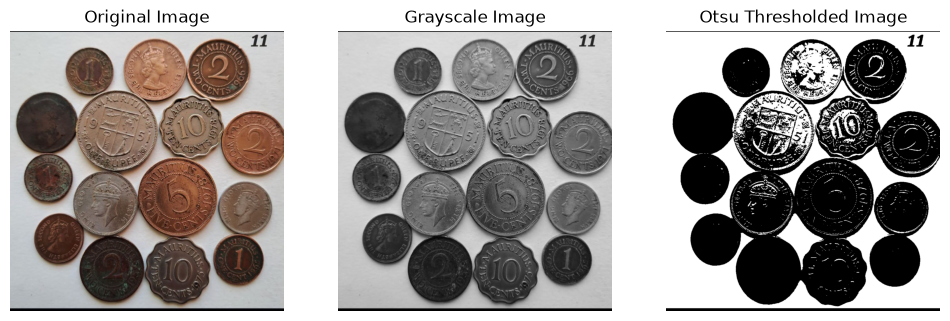

In [20]:
import cv2
import matplotlib.pyplot as plt

# -----------------------------------------
# Step 1: Read the image
# -----------------------------------------
image = cv2.imread("Images/Image8.jpeg")

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

# -----------------------------------------
# Step 2: Convert image to grayscale
# -----------------------------------------
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# -----------------------------------------
# Step 3: Apply Otsu Thresholding
# -----------------------------------------
threshold_value, otsu_image = cv2.threshold(
    gray,
    0,                         # Initial threshold ignored by Otsu
    255,                       # Maximum pixel value
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# -----------------------------------------
# Step 4: Display calculated threshold
# -----------------------------------------
print("Optimal Otsu Threshold =", threshold_value)

# -----------------------------------------
# Step 5: Display results
# -----------------------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_image, cmap="gray")
plt.title("Otsu Thresholded Image")
plt.axis("off")

plt.show()

### Question
**Compare OTSU output with Global thresholding output.**
> Otsu thresholding generally provides better results because it automatically selects the threshold based on the image histogram. Global thresholding depends on the chosen value and may lose details if the value is too high or too low.

## Task 2
Run the program KmeansClustering.ipynb with different fruit images. 

Repeat with different values of K (2,3,4,5).

Images to try:
- Fruit1.jpg
- Fruit4.jpg
- Fruit6.jpg
- Fruit7.jpg

In [25]:
import cv2
import numpy as np

# -----------------------------------
# 1. Read the input image
# -----------------------------------
image = cv2.imread("Images/Fruit1.jpg")

if image is None:
    print("Error: Image not found.")
    exit()

# -----------------------------------
# 2. Convert image into pixel samples
# -----------------------------------
# Original shape: (height, width, 3)
# Reshape into: (number_of_pixels, 3)

pixel_values = image.reshape((-1, 3))

# K-means requires floating-point values
pixel_values = np.float32(pixel_values)

# -----------------------------------
# 3. Define K-means parameters
# -----------------------------------

# Number of clusters / segments
K = 5

# Termination criteria:
# Stop after 100 iterations OR when accuracy reaches 0.2
criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# -----------------------------------
# 4. Apply K-means clustering
# -----------------------------------
compactness, labels, centers = cv2.kmeans(
    pixel_values,
    K,
    None,
    criteria,
    10,
    cv2.KMEANS_PP_CENTERS
)

# -----------------------------------
# 5. Convert cluster centres back
#    to 8-bit pixel values
# -----------------------------------
centers = np.uint8(centers)

# Assign the corresponding cluster
# colour to every pixel
segmented_pixels = centers[labels.flatten()]

# -----------------------------------
# 6. Reshape back to image dimensions
# -----------------------------------
segmented_image = segmented_pixels.reshape(image.shape)

# -----------------------------------
# 7. Display results
# -----------------------------------
cv2.imshow("Original Image", image)
cv2.imshow("K-Means Segmented Image", segmented_image)

cv2.waitKey(0)
cv2.destroyAllWindows()

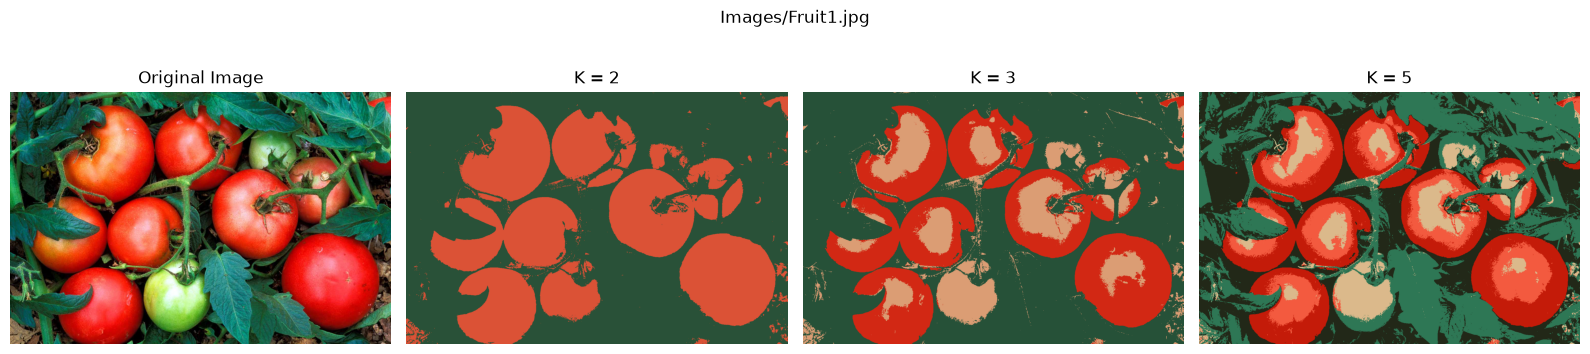

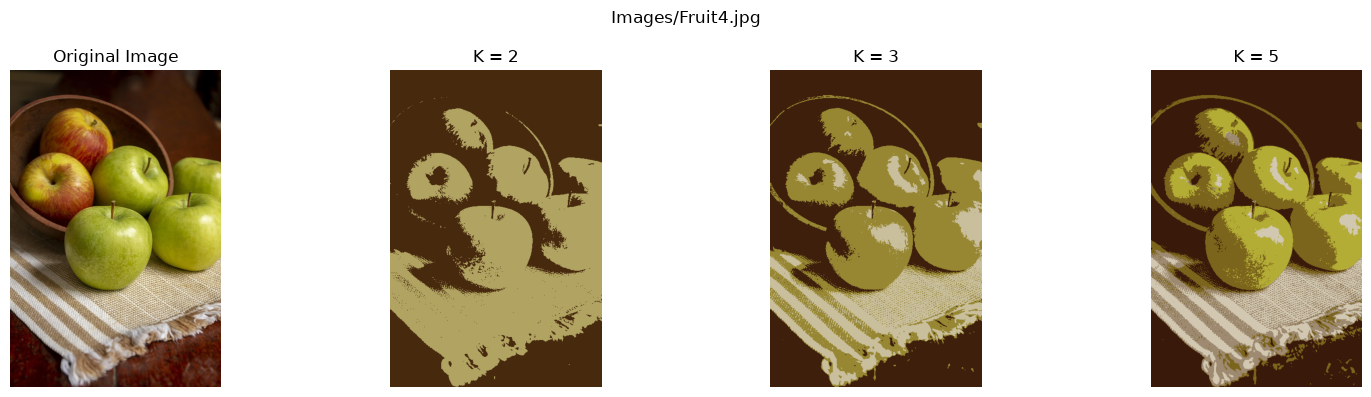

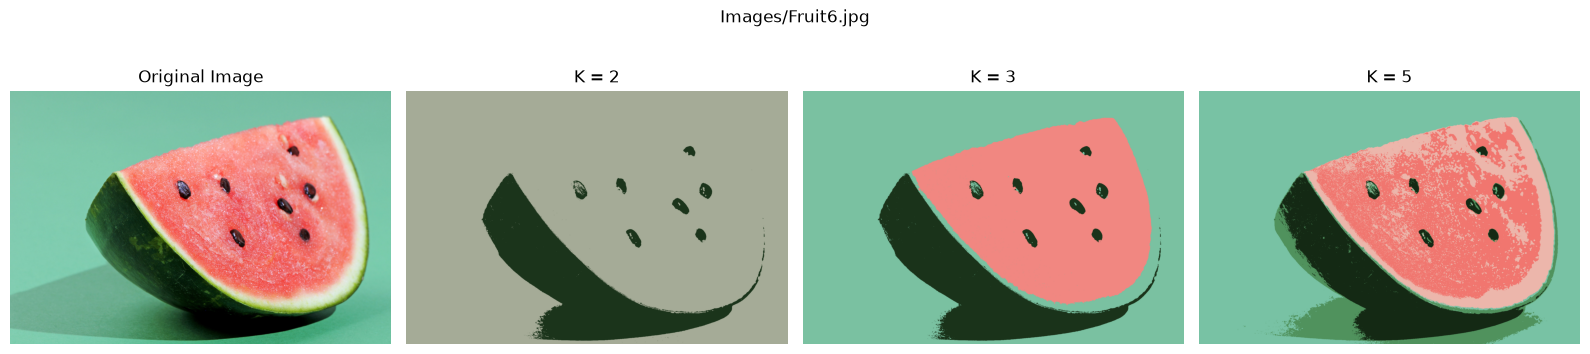

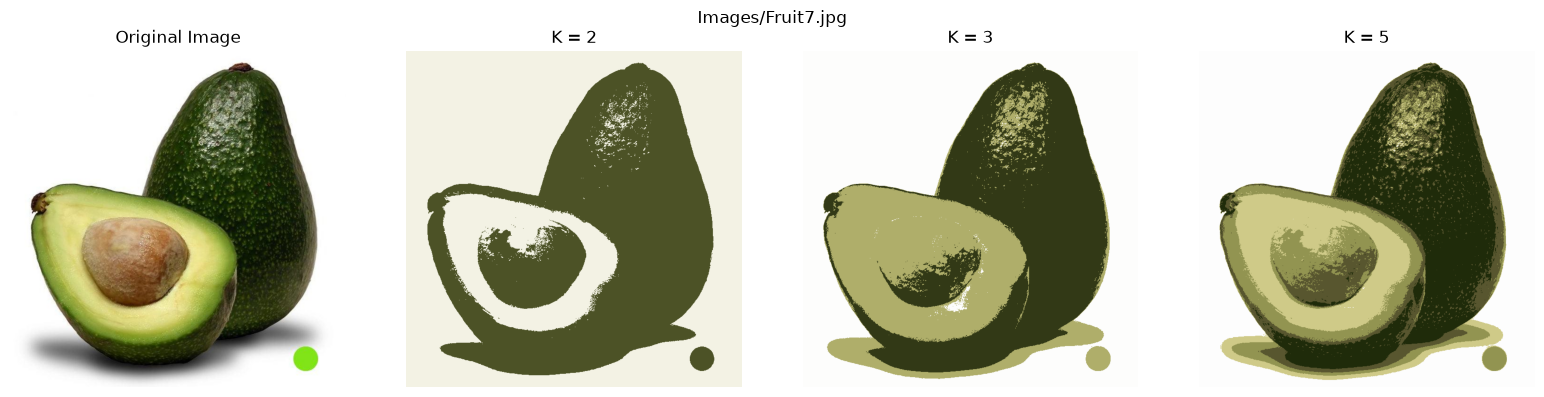

In [15]:
# Display K-means segmentation for each fruit image
image_paths = [
    "Images/Fruit1.jpg",
    "Images/Fruit4.jpg",
    "Images/Fruit6.jpg",
    "Images/Fruit7.jpg"
]

k_values = [2, 3, 5]

for image_path in image_paths:
    original = cv2.imread(image_path)

    if original is None:
        print(f"Could not load: {image_path}")
        continue

    pixels = np.float32(original.reshape((-1, 3)))

    plt.figure(figsize=(16, 4))
    plt.subplot(1, 4, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    for index, k_value in enumerate(k_values, start=2):
        _, labels_k, centers_k = cv2.kmeans(
            pixels,
            k_value,
            None,
            criteria,
            10,
            cv2.KMEANS_PP_CENTERS
        )

        centers_k = np.uint8(centers_k)
        segmented_pixels_k = centers_k[labels_k.flatten()]
        segmented_k = segmented_pixels_k.reshape(original.shape)

        plt.subplot(1, 4, index)
        plt.imshow(cv2.cvtColor(segmented_k, cv2.COLOR_BGR2RGB))
        plt.title(f"K = {k_value}")
        plt.axis("off")

    plt.suptitle(image_path)
    plt.tight_layout()
    plt.show()

### Question
**Observe the output and What can you deduce?**
- K-means groups pixels with similar colours into \(K\) clusters.
- With \(K=2\), the image has fewer colour regions and appears more simplified.
- Increasing \(K\) to 3, 4, or 5 preserves more colour and detail but may introduce smaller unnecessary regions.
- The cluster centres represent the average colour of each segment.
- A suitable value of \(K\) balances image detail and simplicity; \(K=4\) or \(K=5\) provides better segmentation for these fruit images.

## Task 3

Run the program Chaincode.ipynb with the different shape images provided.

Images to try:
- Shape1.png
- Shape2.png
- Shape3.png
- Shape4.png
- Shape5.png

In [26]:
import cv2
import numpy as np


# ---------------------------------------------------------
# 1. Freeman Chain Code
# ---------------------------------------------------------

# Mapping from movement (dx, dy) to Freeman direction
direction_code = {
    (1, 0): 0,      # Right
    (1, -1): 1,     # Up-right
    (0, -1): 2,     # Up
    (-1, -1): 3,    # Up-left
    (-1, 0): 4,     # Left
    (-1, 1): 5,     # Down-left
    (0, 1): 6,      # Down
    (1, 1): 7       # Down-right
}


def get_chain_code(contour):
    """
    Generate Freeman 8-direction chain code
    from an OpenCV contour.
    """

    # Convert contour from shape (N,1,2) to (N,2)
    points = contour.reshape(-1, 2)

    chain_code = []

    for i in range(len(points)):

        # Current point
        x1, y1 = points[i]

        # Next point
        x2, y2 = points[(i + 1) % len(points)]

        dx = x2 - x1
        dy = y2 - y1

        # Normalize movement to -1, 0 or 1
        dx = int(np.sign(dx))
        dy = int(np.sign(dy))

        if (dx, dy) in direction_code:
            chain_code.append(direction_code[(dx, dy)])

    return chain_code


# ---------------------------------------------------------
# 2. First Difference
# ---------------------------------------------------------

def first_difference(chain_code):
    """
    Compute first difference of the chain code.

    Difference = (next_direction - current_direction) mod 8
    """

    diff = []

    n = len(chain_code)

    for i in range(n):

        current = chain_code[i]
        next_code = chain_code[(i + 1) % n]

        d = (next_code - current) % 8

        diff.append(d)

    return diff


# ---------------------------------------------------------
# 3. Shape Number
# ---------------------------------------------------------

def get_shape_number(chain_code):
    """
    Shape number = lexicographically smallest
    circular shift of the first difference.
    """

    diff = first_difference(chain_code)

    if len(diff) == 0:
        return []

    rotations = []

    for i in range(len(diff)):
        rotation = diff[i:] + diff[:i]
        rotations.append(rotation)

    # Smallest circular sequence
    shape_number = min(rotations)

    return shape_number


# ---------------------------------------------------------
# 4. Load image
# ---------------------------------------------------------

image = cv2.imread("Images/Shape1.png")

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


# ---------------------------------------------------------
# 5. Convert image to binary
# ---------------------------------------------------------

_, binary = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY_INV
)


# If the object is black and background white,
# use THRESH_BINARY_INV instead:
#
# _, binary = cv2.threshold(
#   gray, 127, 255, cv2.THRESH_BINARY_INV
#)

# If the object is white and background black,
# use THRESH_BINARY instead:
#
# _, binary = cv2.threshold(
#   gray, 127, 255, cv2.THRESH_BINARY
#)

# ---------------------------------------------------------
# 6. Extract contours
# ---------------------------------------------------------

contours, hierarchy = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)


# Check that a contour exists
if len(contours) == 0:
    raise ValueError("No contour detected.")


# Select the largest object
contour = max(contours, key=cv2.contourArea)


# ---------------------------------------------------------
# 7. Obtain Chain Code
# ---------------------------------------------------------

chain_code = get_chain_code(contour)

print("Freeman Chain Code:")
print(chain_code)


# ---------------------------------------------------------
# 8. First Difference
# ---------------------------------------------------------

difference = first_difference(chain_code)

print("\nFirst Difference:")
print(difference)


# ---------------------------------------------------------
# 9. Shape Number
# ---------------------------------------------------------

shape_number = get_shape_number(chain_code)

print("\nShape Number:")
print(shape_number)


# ---------------------------------------------------------
# 10. Draw contour
# ---------------------------------------------------------

output = image.copy()

cv2.drawContours(
    output,
    [contour],
    -1,
    (0, 0, 255),
    2
)

cv2.imshow("Original Image", image)
cv2.imshow("Binary Image", binary)
cv2.imshow("Detected Contour", output)

cv2.waitKey(0)
cv2.destroyAllWindows()

Freeman Chain Code:
[6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6


Images/Shape1.png
Chain code: [6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5,

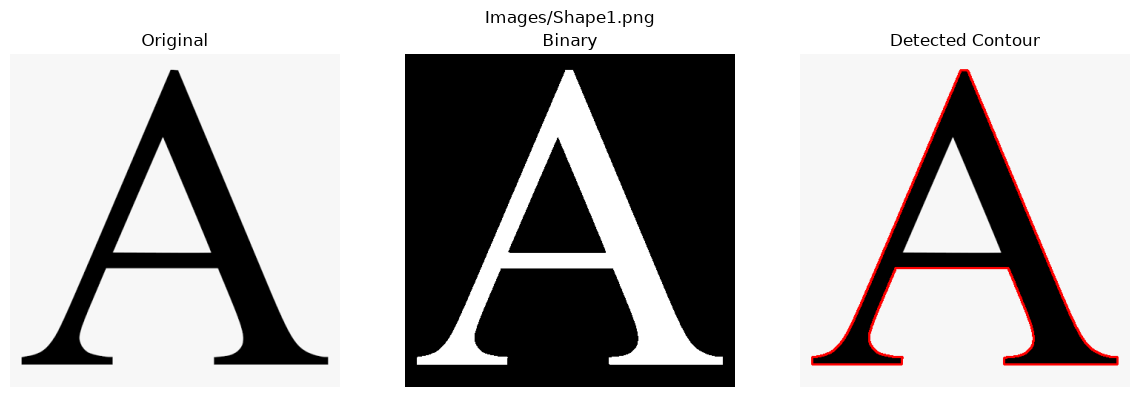


Images/Shape2.png
Chain code: [5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 6, 5, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 0, 7, 7, 7, 7, 7, 6, 0, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 0, 7, 6, 7, 0, 7, 6, 7, 0, 7, 6, 0,

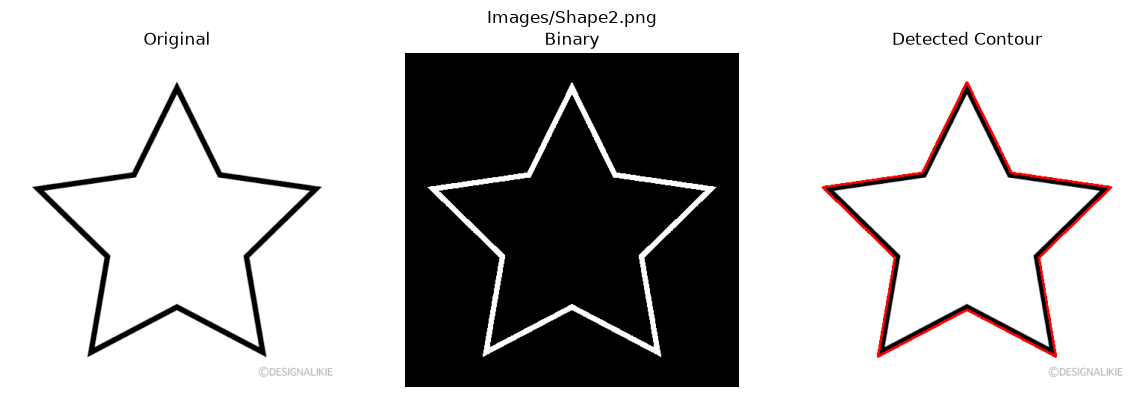


Images/Shape3.png
Chain code: [6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 6, 7, 7, 7, 7, 7, 7, 7, 6, 7, 7, 7, 7, 7, 7, 6, 7, 7, 7, 7, 6, 7, 7, 7, 7, 6, 7, 7, 7, 6, 7, 7, 7, 6, 7, 7, 7, 6, 7, 7, 6, 7, 7, 6, 7, 7, 6, 7, 7, 6, 7, 7, 6, 7, 7, 6, 7, 6, 7, 7, 6, 7, 6, 7, 7, 6, 7, 6, 7, 6, 7, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 6, 7, 6, 7, 6, 7, 6, 6, 7, 6, 7, 6, 6, 7, 6, 6, 7, 6, 7, 6, 6, 7, 6, 6, 7, 6, 6, 7, 6, 6, 6, 7, 6, 6, 7, 6, 6, 6, 7, 6, 6, 6, 7, 6, 6, 6, 6, 7, 6, 6, 6, 6, 7, 6, 6, 6, 6, 7, 6, 6, 6, 6, 6, 6, 7, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 6, 6, 6, 6, 6, 6, 5, 6, 6, 6, 6, 5, 6, 6, 6, 6, 5, 6, 6, 6, 6, 5, 6, 6, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 5, 6, 5, 6, 5, 6, 5, 5, 6, 5, 6, 5, 5, 6,

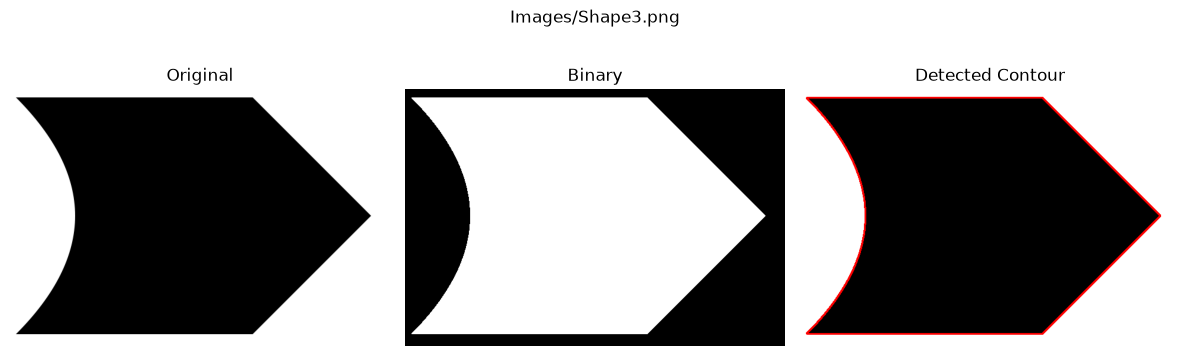


Images/Shape4.png
Chain code: [5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,

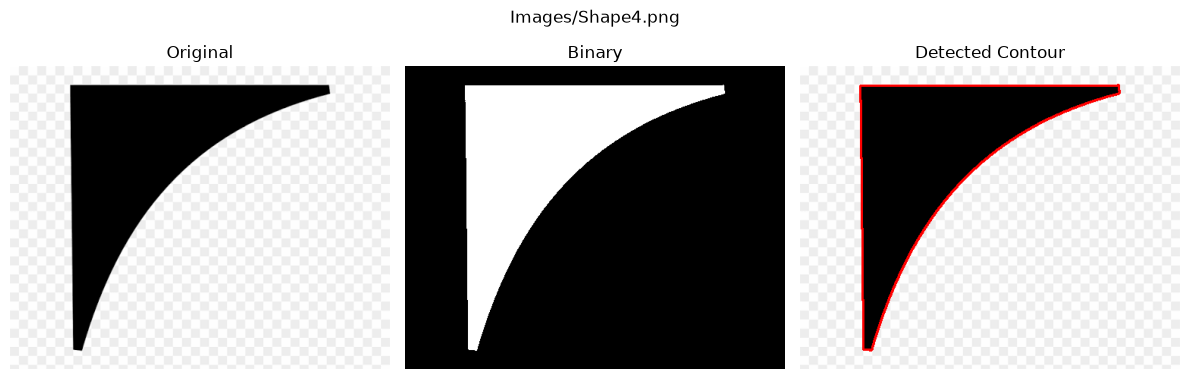


Images/Shape5.png
Chain code: [6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 6, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 0, 7, 7, 7, 0, 7, 7, 7, 0, 7, 7,

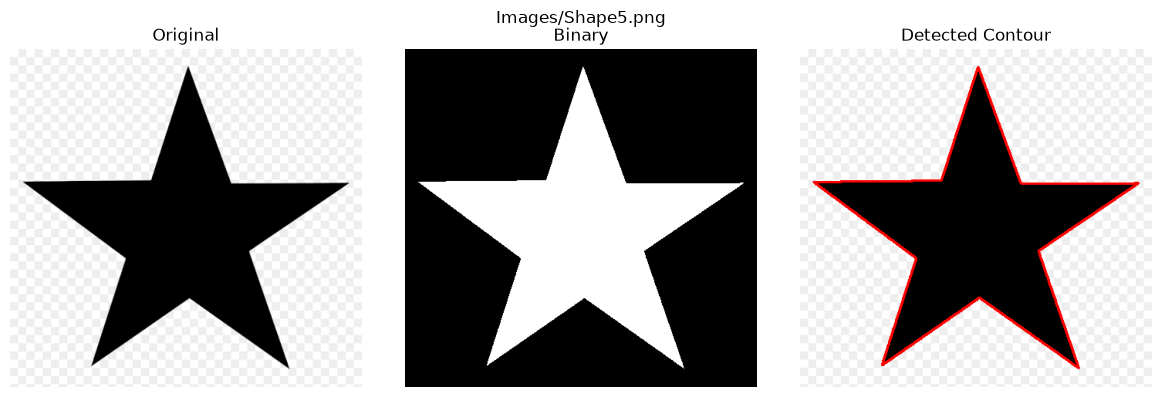

In [27]:
# Perform Freeman Chain Code analysis for all shape images
shape_paths = [
    "Images/Shape1.png",
    "Images/Shape2.png",
    "Images/Shape3.png",
    "Images/Shape4.png",
    "Images/Shape5.png"
]

for shape_path in shape_paths:
    shape_image = cv2.imread(shape_path)

    if shape_image is None:
        print(f"Could not load: {shape_path}")
        continue

    shape_gray = cv2.cvtColor(shape_image, cv2.COLOR_BGR2GRAY)

    _, shape_binary = cv2.threshold(
        shape_gray,
        127,
        255,
        cv2.THRESH_BINARY_INV
    )

    shape_contours, _ = cv2.findContours(
        shape_binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not shape_contours:
        print(f"No contour detected: {shape_path}")
        continue

    shape_contour = max(shape_contours, key=cv2.contourArea)
    shape_chain_code = get_chain_code(shape_contour)
    shape_difference = first_difference(shape_chain_code)
    shape_shape_number = get_shape_number(shape_chain_code)

    shape_output = shape_image.copy()
    cv2.drawContours(
        shape_output,
        [shape_contour],
        -1,
        (0, 0, 255),
        2
    )

    print(f"\n{shape_path}")
    print("Chain code:", shape_chain_code)
    print("First difference:", shape_difference)
    print("Shape number:", shape_shape_number)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(shape_image, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(shape_binary, cmap="gray")
    plt.title("Binary")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(shape_output, cv2.COLOR_BGR2RGB))
    plt.title("Detected Contour")
    plt.axis("off")

    plt.suptitle(shape_path)
    plt.tight_layout()
    plt.show()

### Question
**Observe the output contours carefully and comment on the results: Freeman Chain Code, First Difference, Shape Number**
>The contour was detected successfully as one connected external boundary.
>- **Freeman Chain Code:** The codes are mainly `5` and `6`, showing that the contour mostly moves diagonally and downward along a smooth boundary.
>- **First Difference:** Values such as `0`, `7`, and `1` indicate small, gradual changes in direction. This suggests that the contour has few sharp corners.
>- **Shape Number:** The shape number consists largely of zeros, confirming that the contour is smooth and has a regular outline. It is useful for comparing the shape independently of its starting point and position.

That's it. Thank you for watching!

In [ ]:
Shape1.png